# Блок 8 · Самостоятельная практика (TODO) по компьютерному зрению
## Нейросеть распознаёт рукописные цифры от 0 до 9

**Для начинающих. Без сложной математики и без скачивания датасета.**

Что вы сделаете: откроете картинки с цифрами → обучите небольшую нейросеть → проверите её на незнакомых изображениях → сравните настройки → попробуете нарисовать цифру самостоятельно → объясните результат на экзамене.

**Что является входом и выходом?** На вход подаётся чёрно-белая картинка размером **8 × 8 пикселей**. На выходе — распознанная цифра **0–9** и оценка уверенности модели.

> Это учебный набор `load_digits` из `scikit-learn`. Он меньше, чем MNIST (там 28 × 28), поэтому подходит для быстрого запуска даже без GPU (ускорителя вычислений). Датасет доступен вместе с библиотекой: интернет для скачивания картинок не нужен.

### Путь работы — всего 6 шагов

**Картинки → Подготовка → Нейросеть → Обучение → Проверка → Новая цифра**

В нейросети мы не будем вручную изучать формулы градиентов и свёрток. Нужно понять: **на каких примерах она учится, что предсказывает, как мы измеряем её ошибки и что меняется от настроек**.

Работайте **сверху вниз**, запускайте ячейки кнопкой ▶. В Google Colab выберите *Среда выполнения → Выполнить все*, в VS Code — *Run All*.

## Ячейка 1. Подключаем библиотеки

`sklearn` даёт готовые фотографии цифр, `torch` помогает обучить нейросеть, а `matplotlib` показывает картинки и графики. **Никаких регистраций и API-ключей.**

В обычном Google Colab библиотеки, как правило, уже установлены. Если появляется `ModuleNotFoundError`, выполните отдельно `%pip install torch scikit-learn matplotlib pandas`.

In [24]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42  # один и тот же пример на компьютерах студентов
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)  # быстро и стабильно работает на обычном CPU

print('PyTorch:', torch.__version__)
print('Всё готово: библиотеки подключены!')

PyTorch: 2.14.1+cpu
Всё готово: библиотеки подключены!


## Ячейка 2. Загружаем цифры и смотрим изображения

В наборе **1 797** картинок рукописных цифр. Каждая картинка — маленькая таблица яркости 8 × 8. Метка (`target`) означает **правильную цифру** на картинке.

**Пиксель** — одна маленькая точка изображения. У нас яркость точки от 0 (чёрный) до 16 (яркий). Это и есть входные данные для нейросети.

Количество картинок: 1797
Форма одного изображения: (8, 8)
Возможные ответы: [0 1 2 3 4 5 6 7 8 9]


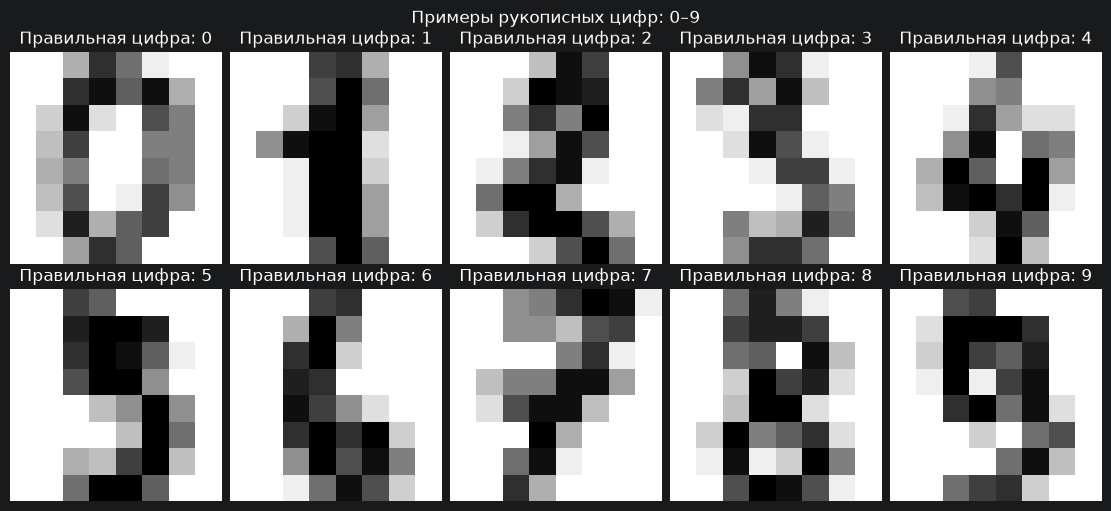

In [25]:
digits = load_digits()

images = digits.images.astype('float32')   # массив (1797, 8, 8)
labels = digits.target.astype('int64')     # правильная цифра 0...9

print('Количество картинок:', len(images))
print('Форма одного изображения:', images[0].shape)
print('Возможные ответы:', np.unique(labels))

fig, axes = plt.subplots(2, 5, figsize=(11, 5), constrained_layout=True)

for digit in range(10):
    idx = int(np.flatnonzero(labels == digit)[0])
    ax = axes.flat[digit]
    ax.imshow(images[idx], cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Правильная цифра: {digit}')
    ax.axis('off')

fig.suptitle('Примеры рукописных цифр: 0–9')
# plt.tight_layout()
plt.show()

assert len(images) == 1797
assert images.shape[1:] == (8, 8)
assert set(np.unique(labels)) == set(range(10))

## Ячейка 3. Делим данные честно

Нейросеть должна распознавать **новые картинки**, а не повторять выученные.

- **Train (обучение)** — картинки, на которых модель учится.
- **Validation (проверка настроек)** — картинки, на которых сравниваем параметры.
- **Test (экзамен для модели)** — отдельные картинки, которые используем для окончательной оценки, только после выбора настроек.

Здесь доли приблизительно **70% / 15% / 15%**. Параметр `stratify` сохраняет примерно одинаковые пропорции цифр в трёх частях.

In [36]:
# 15% оставляем для окончательной проверки
X_dev, X_test, y_dev, y_test = train_test_split(
    images, labels, test_size=0.15, random_state=SEED, stratify=labels
)
# Из оставшихся 85% выделяем ещё около 15% всех данных для validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15/0.85, random_state=SEED, stratify=y_dev
)

# Переводим яркость 0...16 в 0...1 и добавляем канал картинки
# Было: (количество, 8, 8); стало: (количество, 1, 8, 8)
def to_tensor(pictures):
    return torch.tensor(pictures[:, None, :, :] / 16.0, dtype=torch.float32)

T_train, T_val, T_test = map(to_tensor, [X_train, X_val, X_test])
Y_train = torch.tensor(y_train, dtype=torch.long)
Y_val = torch.tensor(y_val, dtype=torch.long)

print(f'Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}')
print('Форма одного входа:', tuple(T_train[0].shape))

assert len(X_train) + len(X_val) + len(X_test) == len(images)
assert T_train.shape[1:] == (1, 8, 8)

Train: 1257 | Validation: 270 | Test: 270
Форма одного входа: (1, 8, 8)


## Ячейка 4. Ваш эксперимент: меняем только три настройки

**Это главная ячейка для самостоятельной работы.** В каждой строке — отдельный опыт.

- `epochs` — сколько раз сеть проходит по обучающим картинкам. Обычно больше = учится дольше, но не всегда лучше.
- `channels` — сколько разных визуальных признаков сеть пытается изучать одновременно. Больше = модель сложнее.
- `learning_rate` — скорость изменения настроек нейросети. Слишком большое значение мешает учиться, слишком маленькое замедляет процесс.

**TODO для студента:** измените числа во второй и третьей строке, повторите обучение и посмотрите, как поменялась точность **Validation**. Названия опытов можно менять. Не меняйте тестовые данные.

In [39]:
# TODO: составьте собственные опыты, изменив хотя бы два параметра
from itertools import product
epochs   = [2 * i for i in range(1, 11)]
channels = [2 * i for i in range(1, 9)]
rate     = [10 ** (-k) for k in range(5, 0, -1)]
EXPERIMENTS = [
    {
        "name": f"ep {e} - ch {c} - lr - {r}", "epochs": e, "channels": c, "learning_rate": r
    }
    for e, c, r in product(epochs, channels, rate)
]

BATCH_SIZE = 64  # сколько изображений сеть обрабатывает за один маленький шаг

print(pd.DataFrame(EXPERIMENTS).to_string(index=False))
assert len(EXPERIMENTS) >= 2
assert all(e['epochs'] > 0 and e['channels'] > 0 and e['learning_rate'] > 0 for e in EXPERIMENTS)

                       name  epochs  channels  learning_rate
   ep 2 - ch 2 - lr - 1e-05       2         2        0.00001
  ep 2 - ch 2 - lr - 0.0001       2         2        0.00010
   ep 2 - ch 2 - lr - 0.001       2         2        0.00100
    ep 2 - ch 2 - lr - 0.01       2         2        0.01000
     ep 2 - ch 2 - lr - 0.1       2         2        0.10000
   ep 2 - ch 4 - lr - 1e-05       2         4        0.00001
  ep 2 - ch 4 - lr - 0.0001       2         4        0.00010
   ep 2 - ch 4 - lr - 0.001       2         4        0.00100
    ep 2 - ch 4 - lr - 0.01       2         4        0.01000
     ep 2 - ch 4 - lr - 0.1       2         4        0.10000
   ep 2 - ch 6 - lr - 1e-05       2         6        0.00001
  ep 2 - ch 6 - lr - 0.0001       2         6        0.00010
   ep 2 - ch 6 - lr - 0.001       2         6        0.00100
    ep 2 - ch 6 - lr - 0.01       2         6        0.01000
     ep 2 - ch 6 - lr - 0.1       2         6        0.10000
   ep 2 - ch 8 - lr - 1e

## Ячейка 5. Как устроена маленькая нейросеть

Для распознавания картинок используем **CNN** (свёрточную нейросеть). Не требуется запоминать код всех слоёв:

**Картинка 8×8 → поиск линий и элементов → сжатие картинки → 10 ответов (0–9)**.

Когда сеть ищет линии или элементы цифр, она использует маленькие вычислительные фильтры. Их параметры она подбирает сама в процессе обучения. В коде ниже устройство модели спрятано в функцию, чтобы дальше вы могли заниматься результатами и экспериментами.

In [40]:
def create_model(channels):
    """Очень маленькая CNN: достаточно для учебных цифр 8x8."""
    return nn.Sequential(
        nn.Conv2d(1, channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),          # картинка 8x8 -> 4x4
        nn.Conv2d(channels, channels * 2, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(channels * 2 * 4 * 4, 10),  # один числовой балл для каждой цифры
    )

print('Маленькая CNN подготовлена:')
print(create_model(channels=4))

Маленькая CNN подготовлена:
Sequential(
  (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(4, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linear(in_features=128, out_features=10, bias=True)
)


## Ячейка 6. Обучаем модель и проверяем качество

Каждый раз сеть делает три простые вещи: **показываем картинки → сравниваем ответы с правильными → исправляем настройки**. Вся «математика» выполняется библиотекой PyTorch.

Что вы увидите после запуска: для каждого опыта количество эпох, `Accuracy` на Validation и `F1` на Validation.

**Accuracy** — доля распознанных правильно картинок. Например, 0.96 означает 96 из 100. **F1** — дополнительная метрика качества, полезная, когда важно качество по всем десяти цифрам; здесь используем среднее по классам.

In [41]:
def train_one(experiment):
    # Повторяемые результаты: одинаковый старт для каждого опыта
    torch.manual_seed(SEED)
    model = create_model(experiment['channels'])
    optimizer = torch.optim.Adam(model.parameters(), lr=experiment['learning_rate'])
    loss_fn = nn.CrossEntropyLoss()  # число ошибки; меньше — обычно лучше
    loader = DataLoader(
        TensorDataset(T_train, Y_train), batch_size=BATCH_SIZE,
        shuffle=True, generator=torch.Generator().manual_seed(SEED)
    )
    history = []
    for epoch in range(experiment['epochs']):
        model.train()
        total_loss = 0.0
        for batch_images, batch_labels in loader:
            optimizer.zero_grad()
            answers = model(batch_images)
            loss = loss_fn(answers, batch_labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch_images)
        # Точность на validation не участвует в обучении, только в сравнении
        model.eval()
        with torch.no_grad():
            val_pred = model(T_val).argmax(dim=1).numpy()
        history.append({
            'epoch': epoch + 1,
            'train_loss': total_loss / len(T_train),
            'val_accuracy': accuracy_score(y_val, val_pred),
        })
    return model, pd.DataFrame(history), val_pred

models = {}
histories = {}
results = []
for experiment in EXPERIMENTS:
    model_run, history_run, val_prediction = train_one(experiment)
    name = experiment['name']
    models[name] = model_run
    histories[name] = history_run
    results.append({
        'опыт': name,
        'эпох': experiment['epochs'],
        'каналов': experiment['channels'],
        'скорость': experiment['learning_rate'],
        'Validation Accuracy': accuracy_score(y_val, val_prediction),
        'Validation F1': f1_score(y_val, val_prediction, average='macro'),
    })

results_df = pd.DataFrame(results).sort_values('Validation Accuracy', ascending=False)
display(results_df.round(4))
print('Лучший опыт определяем по Validation, НЕ по Test.')

assert len(results_df) == len(EXPERIMENTS)
assert results_df['Validation Accuracy'].between(0, 1).all()

,опыт,эпох,каналов,скорость,Validation Accuracy,Validation F1
398,ep 20 - ch 16 - lr - 0.01,20,16,0.01,0.9815,0.9816
238,ep 12 - ch 16 - lr - 0.01,12,16,0.01,0.9778,0.9781
348,ep 18 - ch 12 - lr - 0.01,18,12,0.01,0.9778,0.9779
358,ep 18 - ch 16 - lr - 0.01,18,16,0.01,0.9778,0.9780
388,ep 20 - ch 12 - lr - 0.01,20,12,0.01,0.9778,0.9778
...,...,...,...,...,...,...
175,ep 10 - ch 8 - lr - 1e-05,10,8,0.00,0.0852,0.0521
135,ep 8 - ch 8 - lr - 1e-05,8,8,0.00,0.0778,0.0484
95,ep 6 - ch 8 - lr - 1e-05,6,8,0.00,0.0704,0.0440
55,ep 4 - ch 8 - lr - 1e-05,4,8,0.00,0.0667,0.0412


Лучший опыт определяем по Validation, НЕ по Test.


## Ячейка 7. Сравниваем результаты на графиках

На первом графике видно, насколько разные настройки помогли распознаванию. На втором — как по эпохам уменьшалась ошибка обучения. Важно: **больше эпох или более сложная сеть не обязательно означает выше точность**.

**TODO:** выберите победивший опыт и объясните, какой параметр, вероятно, помог, а какой — нет. Делайте выводы только после просмотра чисел и графиков.

In [47]:
print("columns в results_df:", results_df.columns.tolist())
some_name = next(iter(histories))
print("ключи в histories[name]:", histories[some_name].keys())
print("пример записи:", {k: (type(v).__name__, len(v) if hasattr(v, '__len__') else v)
                         for k, v in histories[some_name].items()})

columns в results_df: ['опыт', 'эпох', 'каналов', 'скорость', 'Validation Accuracy', 'Validation F1']
ключи в histories[name]: Index(['epoch', 'train_loss', 'val_accuracy'], dtype='str')
пример записи: {'epoch': ('Series', 2), 'train_loss': ('Series', 2), 'val_accuracy': ('Series', 2)}


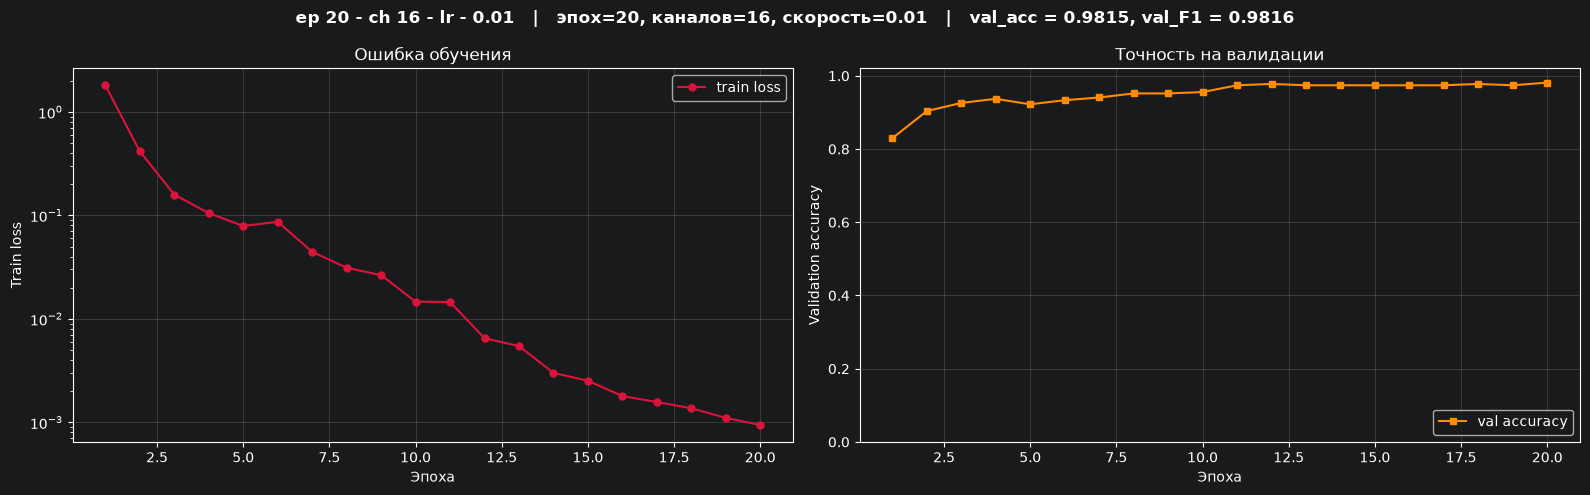

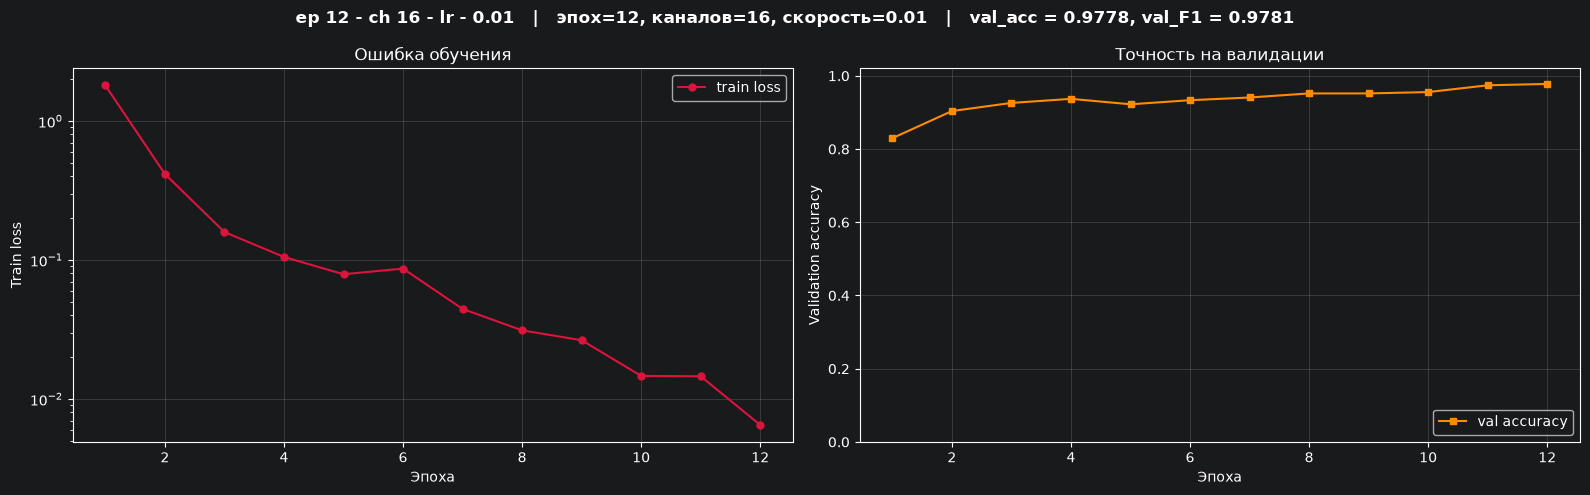

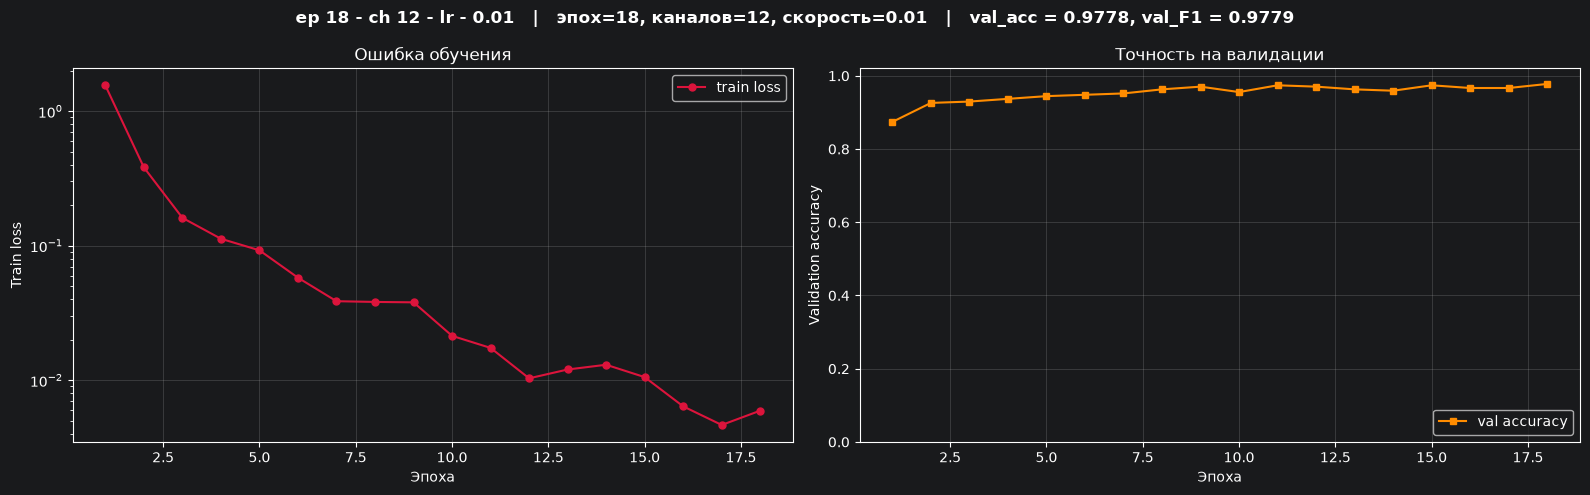

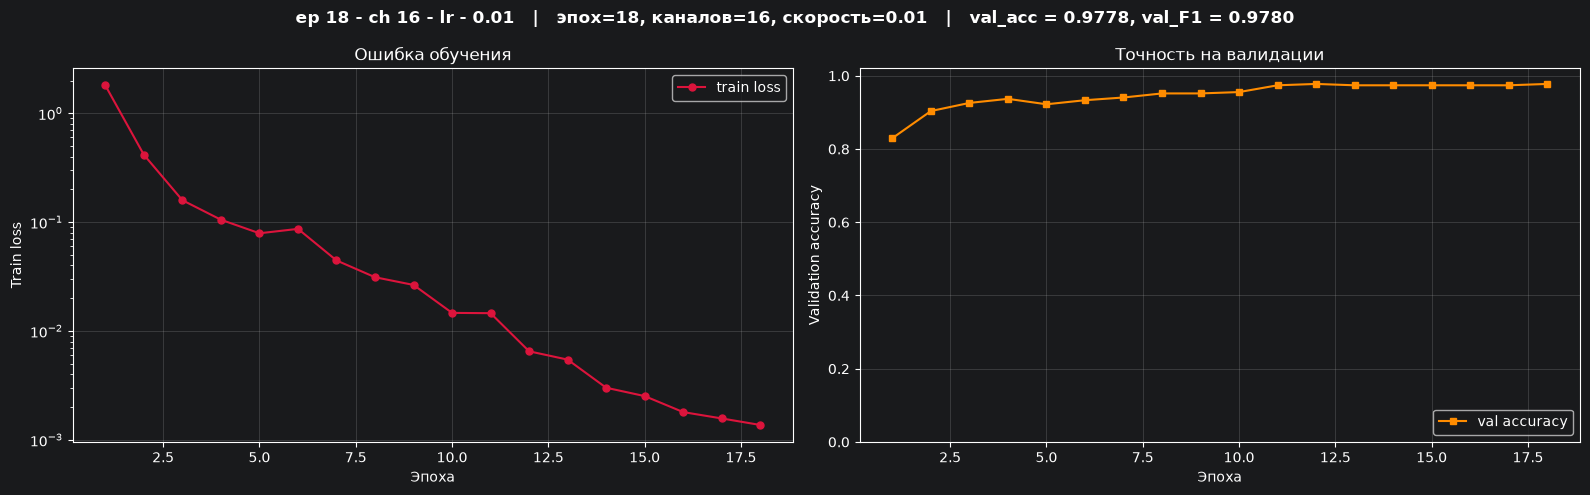

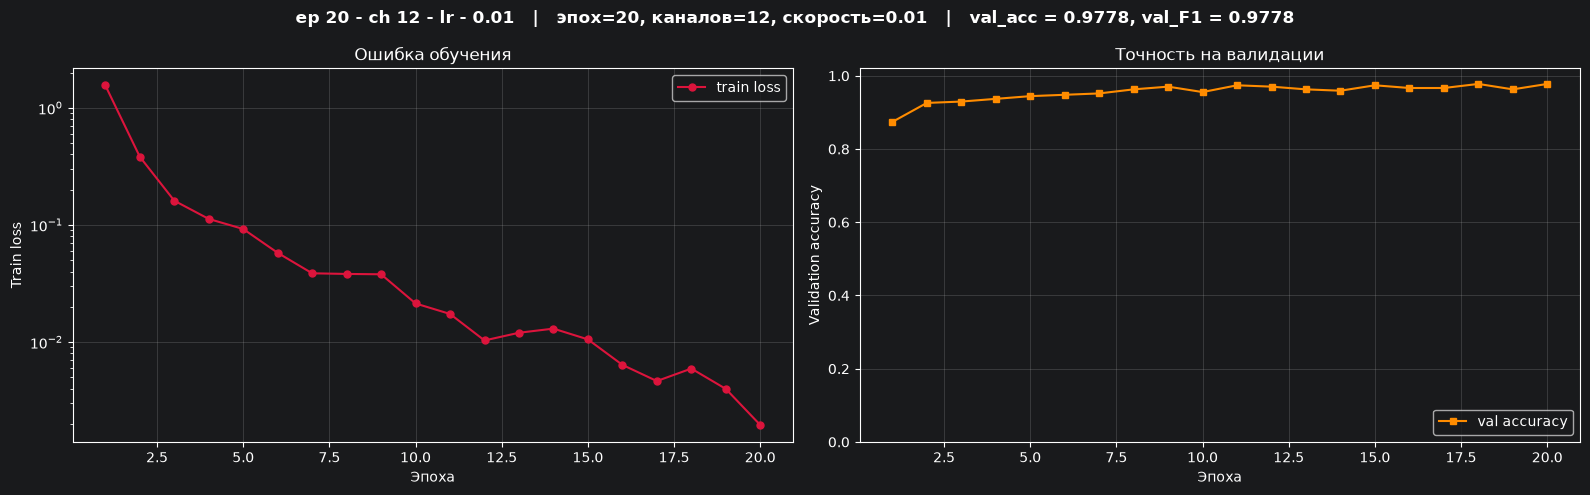

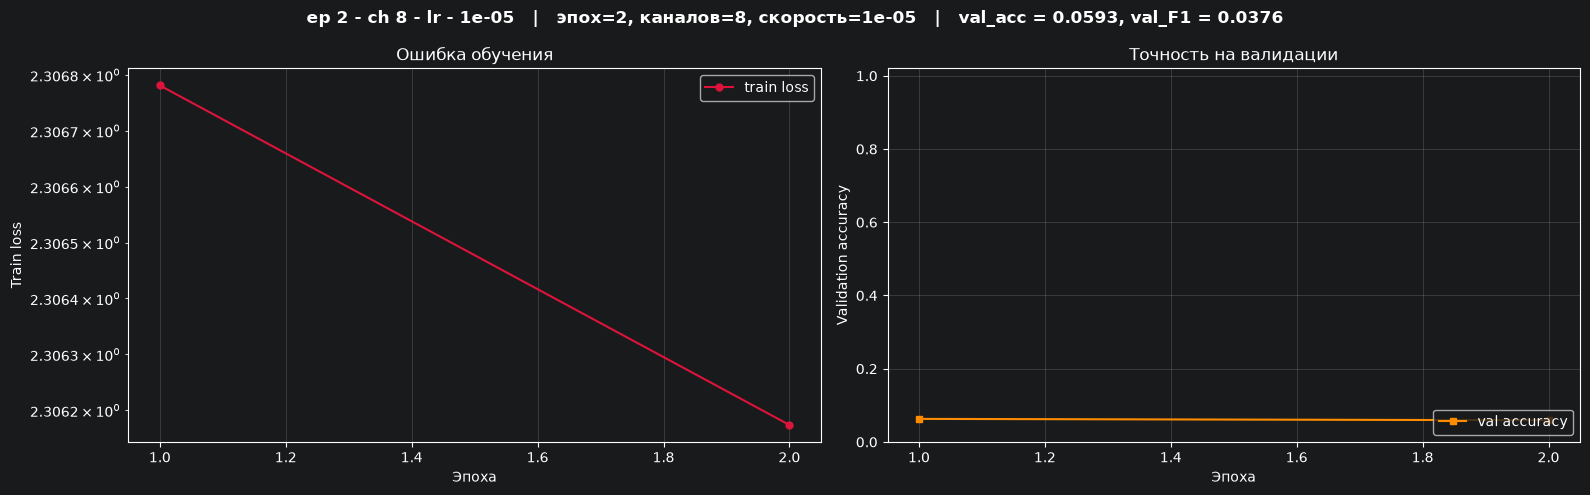

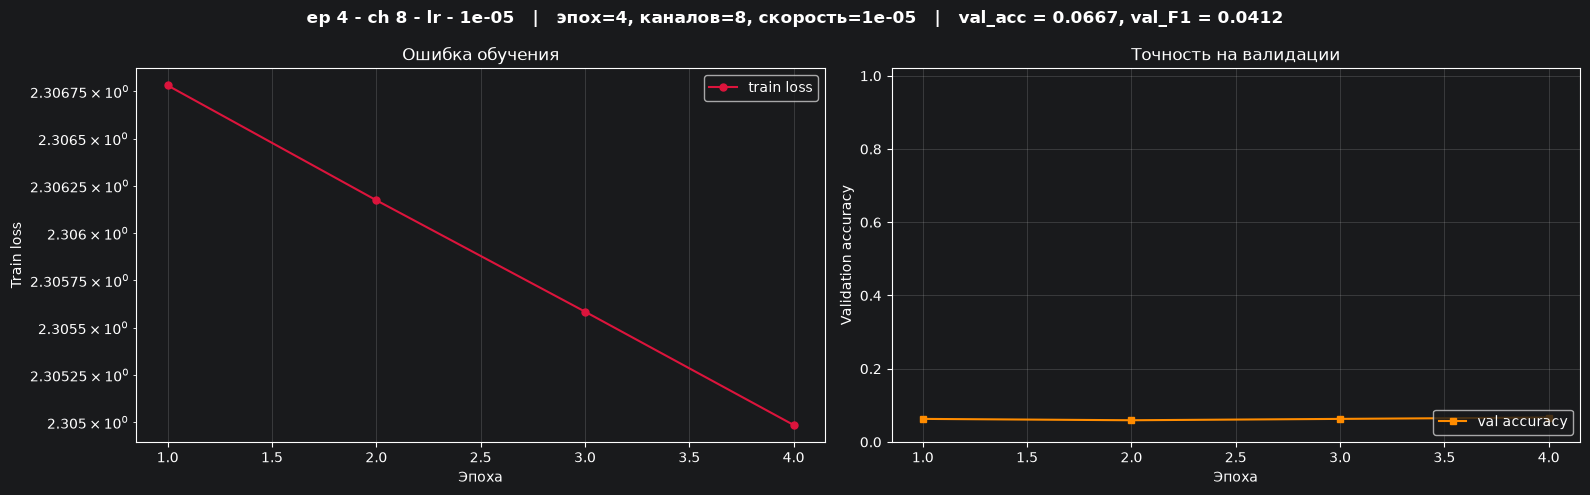

In [49]:
import matplotlib.pyplot as plt

best  = results_df.nlargest(5,  'Validation Accuracy')['опыт'].tolist()
worst = results_df.nsmallest(2, 'Validation Accuracy')['опыт'].tolist()

to_show = best + [n for n in worst if n not in best]
for name in to_show:
    h   = histories[name]
    row = results_df[results_df['опыт'] == name].iloc[0]

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(16, 5))

    # ---------- LOSS ----------
    ax_loss.plot(h['epoch'], h['train_loss'], marker='o', markersize=5,
                 color='crimson', label='train loss')
    ax_loss.set_xlabel('Эпоха')
    ax_loss.set_ylabel('Train loss')
    ax_loss.set_title('Ошибка обучения')
    ax_loss.set_yscale('log')
    ax_loss.grid(True, alpha=0.3)
    ax_loss.legend()

    # ---------- ACCURACY (только val_accuracy) ----------
    ax_acc.plot(h['epoch'], h['val_accuracy'], marker='s', markersize=5,
                color='darkorange', label='val accuracy')
    ax_acc.set_xlabel('Эпоха')
    ax_acc.set_ylabel('Validation accuracy')
    ax_acc.set_title('Точность на валидации')
    ax_acc.set_ylim(0, 1.02)
    ax_acc.grid(True, alpha=0.3)
    ax_acc.legend(loc='lower right')

    # ---------- ЗАГОЛОВОК ----------
    fig.suptitle(
        f"{name}   |   эпох={row['эпох']}, каналов={row['каналов']}, "
        f"скорость={row['скорость']}   |   "
        f"val_acc = {row['Validation Accuracy']:.4f}, "
        f"val_F1 = {row['Validation F1']:.4f}",
        fontsize=12, fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

## Ячейка 8. Окончательная проверка на новых картинках

Выбираем настройки **только по Validation**, а затем **один раз** смотрим качество на отложенной Test-выборке. В настоящем проекте Test не используют, чтобы подбирать параметры: иначе итоговая оценка станет слишком оптимистичной.

Далее увидим `Accuracy`, `F1` и **матрицу ошибок**: какие цифры модель иногда путает.

Выбранная модель: ep 20 - ch 16 - lr - 0.01  (val_acc = 0.981)
Test Accuracy: 0.981 (98.1%)
Test F1 (macro): 0.981

Результат по каждой цифре:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        27
           1      0.931     1.000     0.964        27
           2      1.000     1.000     1.000        27
           3      1.000     1.000     1.000        28
           4      1.000     0.963     0.981        27
           5      1.000     1.000     1.000        27
           6      0.964     1.000     0.982        27
           7      0.931     1.000     0.964        27
           8      1.000     0.885     0.939        26
           9      1.000     0.963     0.981        27

    accuracy                          0.981       270
   macro avg      0.983     0.981     0.981       270
weighted avg      0.983     0.981     0.981       270



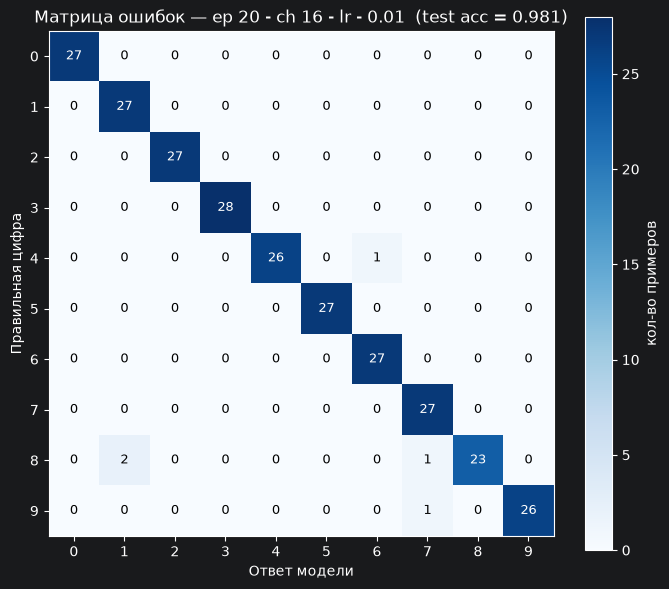

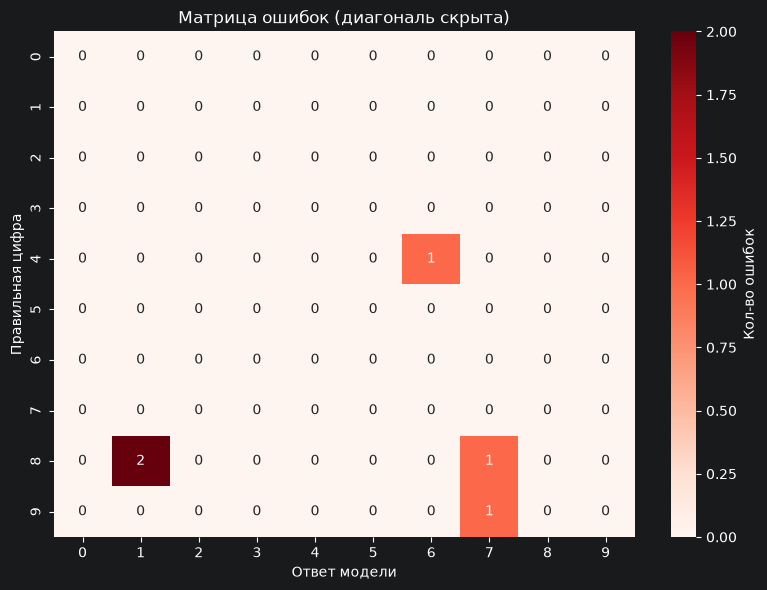

Самые неуверенные предсказания (топ-10):
  idx=  105  y_true=4  pred=4  conf=0.572
  idx=   51  y_true=8  pred=8  conf=0.639
  idx=  166  y_true=9  pred=9  conf=0.684
  idx=  147  y_true=1  pred=1  conf=0.723
  idx=  161  y_true=1  pred=1  conf=0.724
  idx=  227  y_true=9  pred=9  conf=0.838
  idx=  111  y_true=1  pred=1  conf=0.869
  idx=  252  y_true=9  pred=7  conf=0.875
  idx=   38  y_true=7  pred=7  conf=0.889
  idx=   85  y_true=8  pred=8  conf=0.918

Предсказаний с conf >= 0.9: 96.7%
Accuracy на них: 0.985
Accuracy на остальных: 0.889


In [55]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# --- 1. Гарантированно берём ЛУЧШУЮ модель ---
results_sorted = results_df.sort_values('Validation Accuracy', ascending=False).reset_index(drop=True)
BEST_NAME  = str(results_sorted.iloc[0]['опыт'])
best_row   = results_sorted.iloc[0]
best_model = models[BEST_NAME]
best_model.eval()

# --- 2. Устройство ---
device = next(best_model.parameters()).device
T_test = T_test.to(device)

# --- 3. Предсказания ---
with torch.no_grad():
    test_scores     = best_model(T_test)
    probs           = torch.softmax(test_scores, dim=1)
    test_confidence = probs.max(dim=1)[0].cpu().numpy()
    test_predictions = probs.argmax(dim=1).cpu().numpy()

test_acc = accuracy_score(y_test, test_predictions)
test_f1  = f1_score(y_test, test_predictions, average='macro')

print(f'Выбранная модель: {BEST_NAME}  (val_acc = {best_row["Validation Accuracy"]:.3f})')
print(f'Test Accuracy: {test_acc:.3f} ({test_acc*100:.1f}%)')
print(f'Test F1 (macro): {test_f1:.3f}')
print('\nРезультат по каждой цифре:')
print(classification_report(y_test, test_predictions, digits=3, zero_division=0))

# --- 4. Матрица ошибок ---
labels = list(range(10))
matrix = confusion_matrix(y_test, test_predictions, labels=labels)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(matrix, cmap='Blues')
ax.set_xticks(labels); ax.set_yticks(labels)
ax.set_xlabel('Ответ модели'); ax.set_ylabel('Правильная цифра')
ax.set_title(f'Матрица ошибок — {BEST_NAME}  (test acc = {test_acc:.3f})')
for row in range(10):
    for col in range(10):
        v = matrix[row, col]
        color = 'white' if v > matrix.max() / 2 else 'black'
        ax.text(col, row, str(v), ha='center', va='center',
                fontsize=9, color=color)
fig.colorbar(image, ax=ax, label='кол-во примеров')
plt.tight_layout(); plt.show()

# --- 5. Проверки ---
assert len(test_predictions) == len(y_test)
assert matrix.sum() == len(y_test)
assert 0 <= test_acc <= 1


# Копируем матрицу, чтобы не портить оригинал
err_matrix = matrix.copy()
np.fill_diagonal(err_matrix, 0)  # обнуляем диагональ

fig, ax = plt.subplots(figsize=(8, 6))
# Используем красную палитру, чтобы визуально ассоциировать с "ошибкой"
sns.heatmap(err_matrix, annot=True, fmt='d', cmap='Reds',
            cbar_kws={'label': 'Кол-во ошибок'}, ax=ax)

ax.set_xlabel('Ответ модели')
ax.set_ylabel('Правильная цифра')
ax.set_title('Матрица ошибок (диагональ скрыта)')
plt.tight_layout()
plt.show()

print('Самые неуверенные предсказания (топ-10):')
idx_unsure = np.argsort(test_confidence)[:10]
for i in idx_unsure:
    print(f'  idx={i:5d}  y_true={y_test[i]}  pred={test_predictions[i]}  '
          f'conf={test_confidence[i]:.3f}')

# Доля ответов с уверенностью >= 0.9 — «надёжная» часть теста
conf_threshold = 0.9
mask = test_confidence >= conf_threshold
print(f'\nПредсказаний с conf >= {conf_threshold}: {mask.mean()*100:.1f}%')
if mask.any():
    print(f'Accuracy на них: {accuracy_score(y_test[mask], test_predictions[mask]):.3f}')
    print(f'Accuracy на остальных: {accuracy_score(y_test[~mask], test_predictions[~mask]):.3f}')

## Ячейка 9. Посмотрим распознанные и ошибочные цифры

На картинке подпись: **Факт** — что нарисовано на самом деле; **Модель** — что ответила сеть. Если они не совпадают, это ошибка. Самое интересное на экзамене — **объяснить ошибки**, а не скрыть их.

Правильных: 265; ошибочных: 5


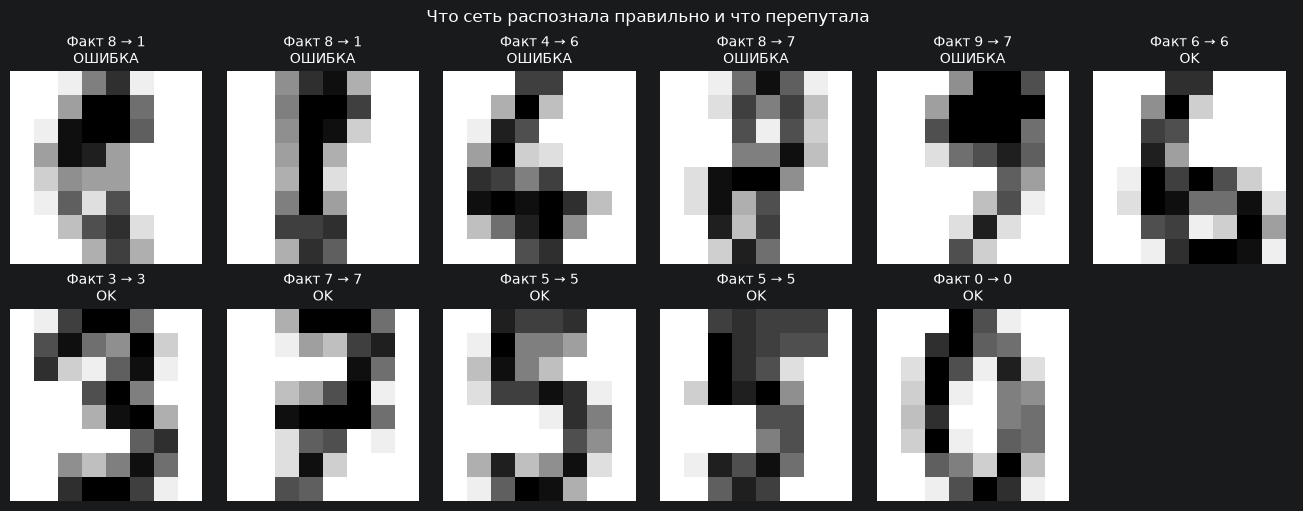

In [58]:
wrong_indices = np.flatnonzero(test_predictions != y_test)
right_indices = np.flatnonzero(test_predictions == y_test)
print(f'Правильных: {len(right_indices)}; ошибочных: {len(wrong_indices)}')

# Покажем до шести ошибок и дополнительно до шести удачных распознаваний
chosen = np.concatenate([wrong_indices[:6], right_indices[:6]])
fig, axes = plt.subplots(2, 6, figsize=(13, 5), constrained_layout=True )
for ax, idx in zip(axes.flat, chosen):
    ax.imshow(X_test[idx], cmap='gray_r', vmin=0, vmax=16)
    ok = 'OK' if y_test[idx] == test_predictions[idx] else 'ОШИБКА'
    ax.set_title(f'Факт {y_test[idx]} → {test_predictions[idx]}\n{ok}', fontsize=10)
    ax.axis('off')
for ax in list(axes.flat)[len(chosen):]:
    ax.axis('off')
plt.suptitle('Что сеть распознала правильно и что перепутала')
plt.show()

## Ячейка 10. Вы вводите новый пример

**Задание для студента:** измените `IMAGE_NUMBER` (от `0` до `len(X_test)-1`) и `NOISE`. Нейросеть увидит другое изображение или ту же цифру с помехами.

- `IMAGE_NUMBER` — номер картинки для проверки.
- `NOISE = 0.0` — исходная картинка; `0.2` или `0.5` — добавляем помехи.

Важно: изображение из Test здесь используется только для **демонстрации уже выбранной модели**; менять по нему обучающие параметры нельзя.

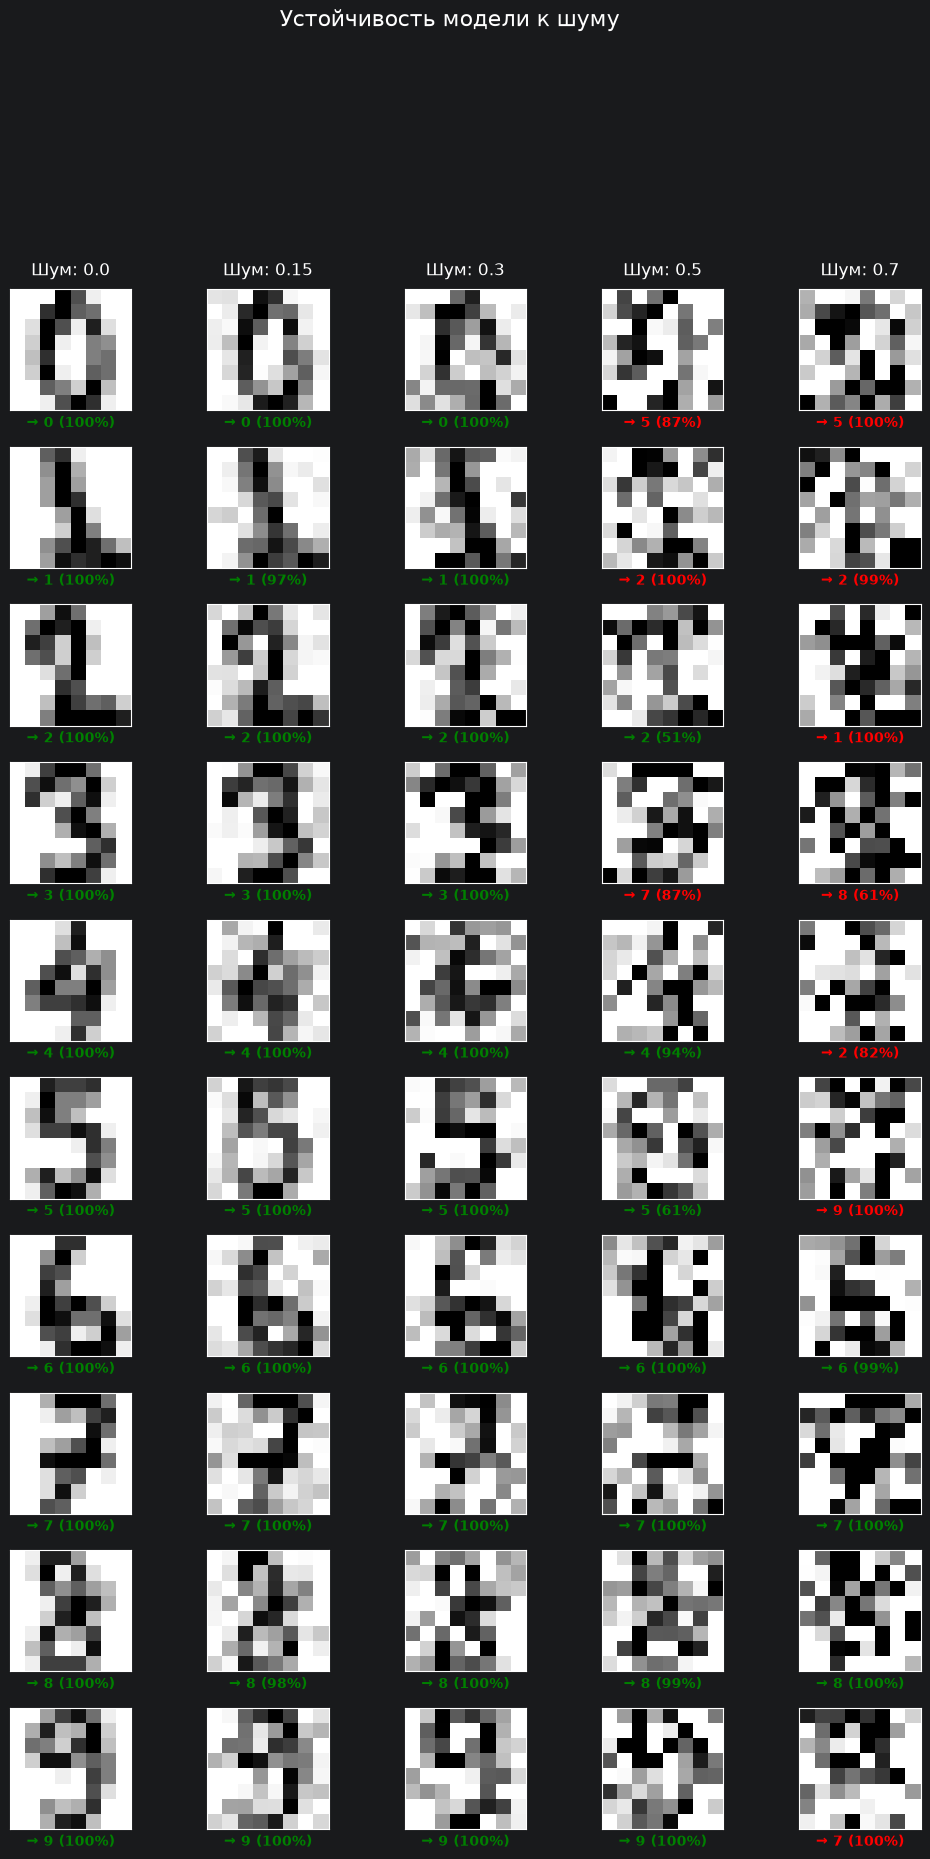

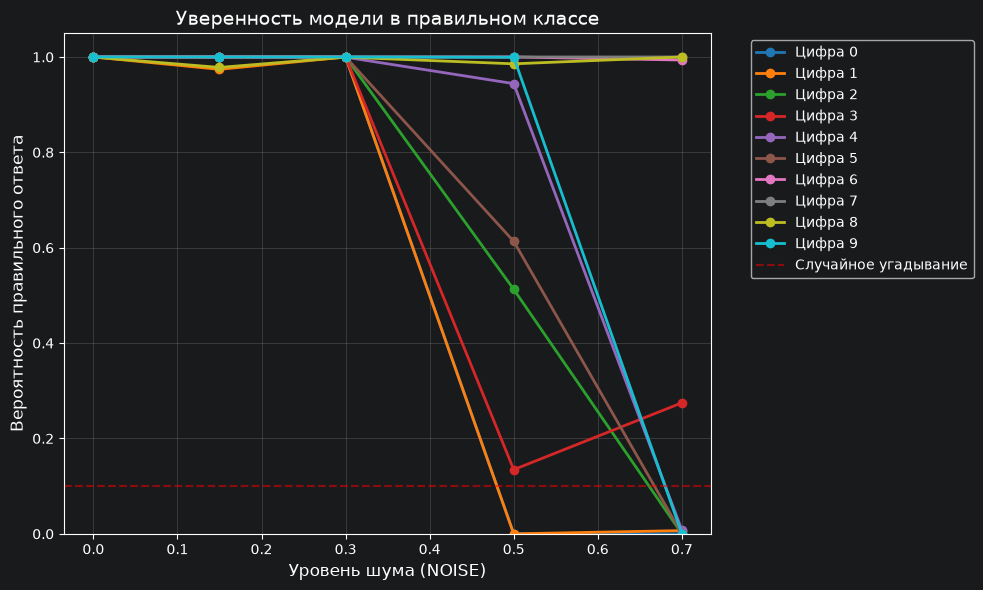

In [65]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Берем ВСЕ 10 цифр (или любой другой список, например [1, 4, 8])
target_digits = list(range(10))  # 0, 1, ..., 9
indices = [np.where(y_test == d)[0][0] for d in target_digits]

# 2. Задаем уровни шума
noise_levels = [0.0, 0.15, 0.3, 0.5, 0.7]

device = next(best_model.parameters()).device
rng = np.random.default_rng(42)

# --- ДИНАМИЧЕСКАЯ СЕТКА ---
n_rows = len(target_digits)
n_cols = len(noise_levels)
# Размер картинки подстраивается: 2.5 дюйма на столбец, 2 дюйма на строку
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.5 * n_cols, 2.0 * n_rows))
# Если вдруг выбрана только 1 строка или 1 столбец, делаем массив двумерным
axes = np.atleast_2d(axes)

plt.subplots_adjust(wspace=0.1, hspace=0.3)

results = {d: {'true_probs': []} for d in target_digits}

for i, idx in enumerate(indices):
    original = X_test[idx] / 16.0
    true_label = y_test[idx]

    for j, noise in enumerate(noise_levels):
        # Добавляем шум
        changed = np.clip(original + rng.normal(0, noise, size=(8, 8)), 0, 1)
        input_tensor = torch.tensor(changed[None, None, :, :], dtype=torch.float32).to(device)

        with torch.no_grad():
            scores = best_model(input_tensor)
            probs = torch.softmax(scores, dim=1).cpu().numpy()[0]

        answer = int(probs.argmax())
        confidence = probs[answer]
        true_class_prob = probs[true_label]

        results[true_label]['true_probs'].append(true_class_prob)

        # --- Отрисовка картинки ---
        ax = axes[i, j]
        ax.imshow(changed, cmap='gray_r', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])

        # Заголовки столбцов (только для первой строки)
        if i == 0:
            ax.set_title(f'Шум: {noise}', fontsize=12, pad=10)

        # Цвет: зеленый если верно, красный если ошибка
        color = 'green' if answer == true_label else 'red'
        alpha = 1.0 if confidence > 0.5 else 0.5

        ax.set_xlabel(f'→ {answer} ({confidence:.0%})',
                      color=color, fontsize=10, fontweight='bold', alpha=alpha)

plt.suptitle('Устойчивость модели к шуму', fontsize=16, y=1.02)
plt.show()

# --- График падения уверенности ---
plt.figure(figsize=(10, 6))
# Берем цвета из палитры tab10 или tab20
cmap = plt.get_cmap('tab10')
colors = [cmap(i % 10) for i in range(len(target_digits))]

for idx, d in enumerate(target_digits):
    plt.plot(noise_levels, results[d]['true_probs'], marker='o',
             linewidth=2, color=colors[idx], label=f'Цифра {d}')

plt.axhline(y=1/10, color='red', linestyle='--', alpha=0.5, label='Случайное угадывание')
plt.xlabel('Уровень шума (NOISE)', fontsize=12)
plt.ylabel('Вероятность правильного ответа', fontsize=12)
plt.title('Уверенность модели в правильном классе', fontsize=14)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Ячейка 11. Нарисуйте СВОЮ цифру в виде маленькой сетки

Это **собственный ввод данных**, а не картинка из обучающего набора. Каждая строка содержит **ровно 8 символов**, всего **8 строк**:

- `.` — чёрная пустая точка;
- `+` — полутон;
- `#` — яркая точка цифры.

Измените символы, чтобы получить **0**, **1**, **2**, **3** или любую другую цифру. Код покажет рисунок и ответ модели.

**Важное ограничение:** такие квадратные символы отличаются от настоящих рукописных цифр. Модель может ошибаться, и это отличный повод обсудить, что происходит с *незнакомым стилем данных*.

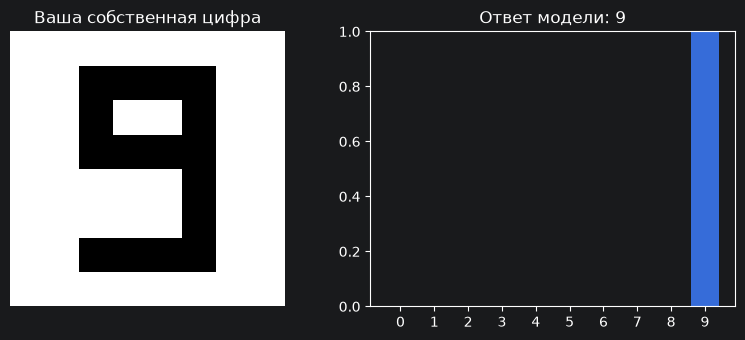

Результат: 9; оценка уверенности: 99.8%


In [66]:
# TODO: попробуйте нарисовать другую цифру в восьми строках
# TODO: меняйте строки, рисуя новую цифру (каждая строка = 8 символов)
MY_DIGIT = [
    '........',
    '..####..',
    '..#..#..',
    '..####..',
    '.....#..',
    '.....#..',
    '..####..',
    '........',
]

assert len(MY_DIGIT) == 8 and all(len(line) == 8 for line in MY_DIGIT)
brightness = {'.': 0.0, '+': 0.5, '#': 1.0}
assert all(ch in brightness for line in MY_DIGIT for ch in line)
user_image = np.array([[brightness[ch] for ch in line] for line in MY_DIGIT], dtype='float32')
with torch.no_grad():
    user_scores = best_model(torch.tensor(user_image[None, None, :, :]))
    user_probs = torch.softmax(user_scores, dim=1).numpy()[0]
user_answer = int(user_probs.argmax())

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(user_image, cmap='gray_r', vmin=0, vmax=1)
axes[0].set_title('Ваша собственная цифра')
axes[0].axis('off')
axes[1].bar(range(10), user_probs)
axes[1].set_xticks(range(10)); axes[1].set_ylim(0, 1)
axes[1].set_title(f'Ответ модели: {user_answer}')
plt.tight_layout(); plt.show()
print(f'Результат: {user_answer}; оценка уверенности: {user_probs[user_answer]:.1%}')

## Ячейка 12. Сохраняем результат для экзамена и GitHub

Сохраняем три вещи: таблицу сравнения настроек, итоговые метрики и параметры обученной модели. Это позволит воспроизвести результат и включить его в ваш отчёт. Файл `.pth` — **веса нейросети**, а не весь код.

Папка `digits_block8_results/` создаётся в текущей рабочей папке ноутбука (в Colab — временно; при необходимости скачайте файлы до окончания сессии).

In [69]:
import json

OUTPUT_DIR = Path('../reports/digits_block8_results')
OUTPUT_DIR.mkdir(exist_ok=True)
results_df.to_csv(OUTPUT_DIR / 'experiments.csv', index=False, encoding='utf-8-sig')
metrics = {
    'dataset': 'sklearn.datasets.load_digits (8x8, 1797 изображений)',
    'best_experiment': BEST_NAME,
    'test_accuracy': float(test_acc),
    'test_f1_macro': float(test_f1),
    'train_size': len(X_train),
    'val_size': len(X_val),
    'test_size': len(X_test),
}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
best_config = next(e for e in EXPERIMENTS if e['name'] == BEST_NAME)
torch.save({'model_state_dict': best_model.state_dict(),
            'channels': best_config['channels'],
            'config': best_config}, OUTPUT_DIR / 'digit_cnn.pth')
print('Файлы сохранены:', [p.name for p in OUTPUT_DIR.iterdir()])

assert (OUTPUT_DIR / 'experiments.csv').exists()
assert (OUTPUT_DIR / 'metrics.json').exists()
assert (OUTPUT_DIR / 'digit_cnn.pth').exists()

Файлы сохранены: ['digit_cnn.pth', 'experiments.csv', 'metrics.json']


In [68]:
import torch
import torch.nn as nn

# 1. Восстанавливаем архитектуру (вам нужно знать класс вашей модели)
# Предположим, он называется DigitCNN и принимает channels как аргумент
def load_trained_model(path):
    # Загружаем словарь (по умолчанию на CPU)
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)

    # Достаем конфиг
    channels = checkpoint['channels']

    # Создаем пустую модель с нужным числом каналов
    model = DigitCNN(channels=channels)

    # Загружаем веса
    model.load_state_dict(checkpoint['model_state_dict'])

    # Переводим в режим инференса
    model.eval()
    return model

# Использование:
# model = load_trained_model('digits_block8_results/digit_cnn.pth')

## Что нужно запомнить — словарь из 10 терминов

| Слово | Простой смысл |
|---|---|
| **Компьютерное зрение** | компьютер анализирует картинки |
| **Пиксель** | точка изображения, здесь число яркости |
| **Датасет** | набор примеров с картинками и правильными цифрами |
| **Нейросеть** | модель, которая подбирает внутренние параметры по примерам |
| **CNN** | нейросеть, удобная для поиска особенностей изображения |
| **Эпоха** | один проход по всем обучающим примерам |
| **Train / Validation / Test** | обучение / сравнение настроек / окончательная проверка |
| **Accuracy** | доля правильно распознанных цифр |
| **Матрица ошибок** | таблица: что было нарисовано и что ответила модель |
| **Переобучение** | модель запомнила обучающие примеры, но плохо работает с новыми |

**Не надо заучивать** производные, градиенты или формулы свёртки. Для этого есть отдельное продвинутое пособие.

## Экзаменационная практическая работа — задания

**Задача:** обучить CNN для распознавания цифр, показать результат на новых картинках и объяснить, как изменяются показатели при смене параметров.

1. Запустите все ячейки без ошибок. Покажите 10 примеров цифр и размер датасета.
2. В ячейке 4 сравните **не менее трёх опытов** с отличающимися параметрами `epochs`, `channels` или `learning_rate`.
3. Покажите таблицу сравнения и графики. Объясните, какой опыт оказался лучшим на **Validation** и почему выбор сделан не по Test.
4. Покажите `Test Accuracy`, матрицу ошибок и минимум две картинки, которые модель распознала неверно (если ошибки есть).
5. В ячейке 10 измените `IMAGE_NUMBER` и `NOISE`. Покажите, как изменился ответ или уверенность модели.
6. В ячейке 11 нарисуйте собственную цифру. Покажите прогноз и объясните, почему он может быть неверным.
7. Сохраните `experiments.csv`, `metrics.json`, ноутбук. Опубликуйте исходный код и README в **GitHub**.

### В отчёте студент заполняет самостоятельно

**Мои три опыта:** ________________________

**Лучшая настройка и её Validation Accuracy:** ________________________

**Итоговая Test Accuracy:** ________________________

**Какие цифры модель путала и почему (моя гипотеза):** ________________________

**Что изменилось при добавлении шума:** ________________________

**Мой вывод: чему я научился:** ________________________

## Контрольные вопросы с ответами

**Что делает нейросеть?** Учится распознавать цифры по примерам изображений и правильных ответов.

**Зачем нужны три части данных?** На Train обучаем, на Validation выбираем настройки, на Test проверяем итоговое качество без подгонки.

**Почему 10 ответов модели?** Цифр десять: от 0 до 9.

**Увеличение epochs всегда улучшает результат?** Нет. Иногда улучшает, иногда почти ничего не меняет, а иногда увеличивает переобучение.

**Почему модель ошибается на собственной нарисованной цифре?** Наш стиль рисунка может отличаться от картинок, на которых она обучалась.

**Зачем нужен GitHub?** Чтобы преподаватель мог увидеть проект, историю изменений, инструкции и результаты.

### Как разместить в GitHub

Создайте репозиторий `block08_digits_cv`, добавьте `.ipynb`, `README.md` и результаты без личных данных. Из VS Code в папке проекта выполните:

```bash
git init
git add .
git commit -m "Add digit recognition notebook and experiment results"
git branch -M main
git remote add origin https://github.com/YOUR_USERNAME/block08_digits_cv.git
git push -u origin main
```

`YOUR_USERNAME` замените на своё имя в GitHub. Команда `git remote add` не нужна, если адрес уже настроен. В README укажите цель, откуда взяты данные, как запускать, ваши три опыта, метрики и ограничения.

## Критерии экзамена (10 баллов)

| Что оценивается | Баллы |
|---|---:|
| Ноутбук полностью запускается; студент понимает вход и выход | 2 |
| Проведены три самостоятельных эксперимента с параметрами | 2 |
| Сравнены результаты, есть объяснение метрик и ошибок | 2 |
| Продемонстрированы новые картинки, шум и собственная цифра | 2 |
| Проект опубликован в GitHub, есть README и защита | 2 |

**Важно:** высокая точность сама по себе не даёт максимальный балл. Гораздо важнее **понимать**, почему модель отвечает так и что меняется при изменении параметров.